# Machine Learning Project 01

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings. filterwarnings("ignore")


In [2]:
df = pd.read_csv("insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


## Exploratory Data Analysis (EDA)

shape of the dataframe

In [3]:
df.shape

(1338, 7)

head of dataframe

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


information of dataframe

In [5]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

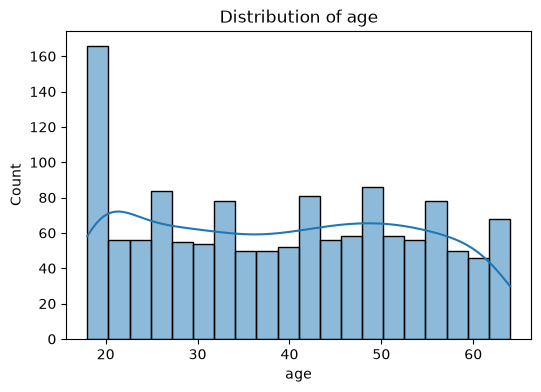

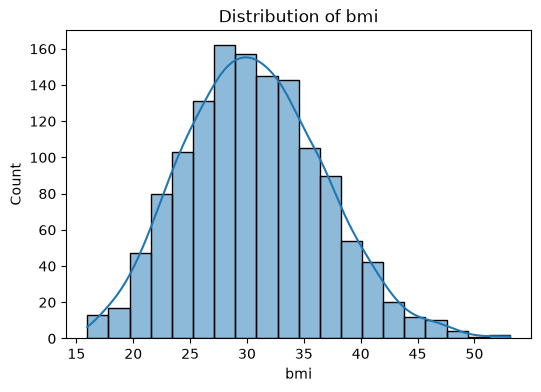

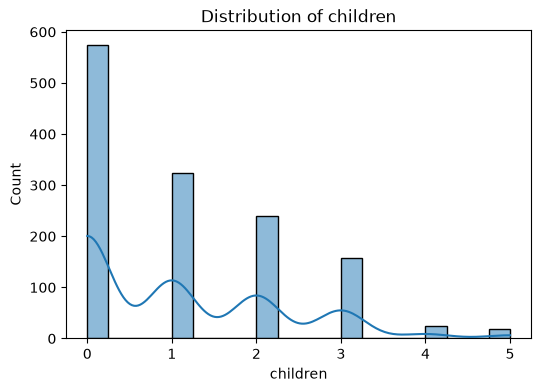

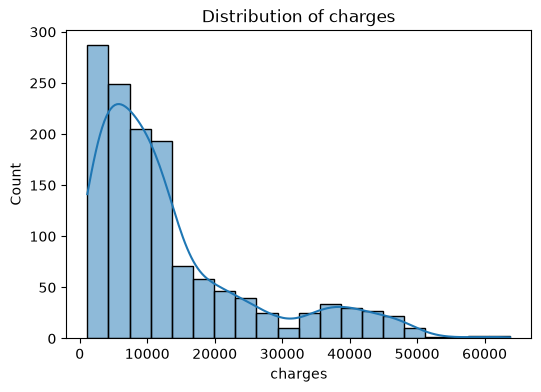

In [8]:
numeric_coloums = ["age","bmi","children","charges"]
for col in numeric_coloums:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde='true', bins= 20)
    plt.title(f"Distribution of {col}")

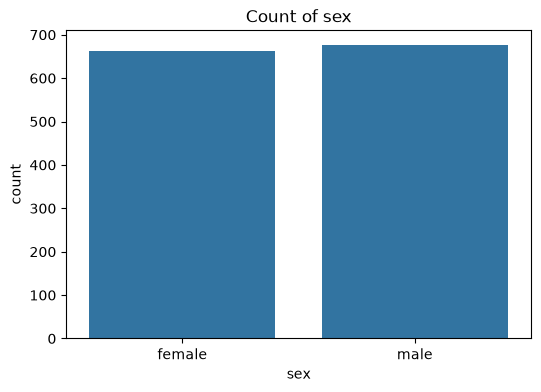

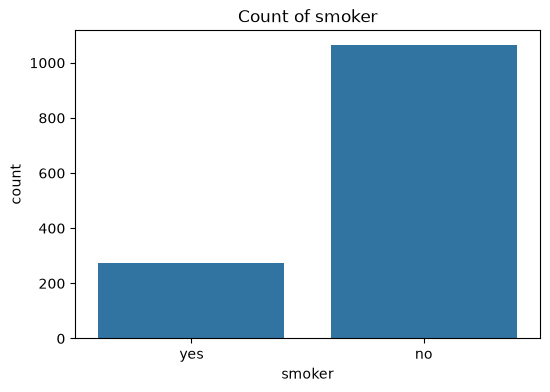

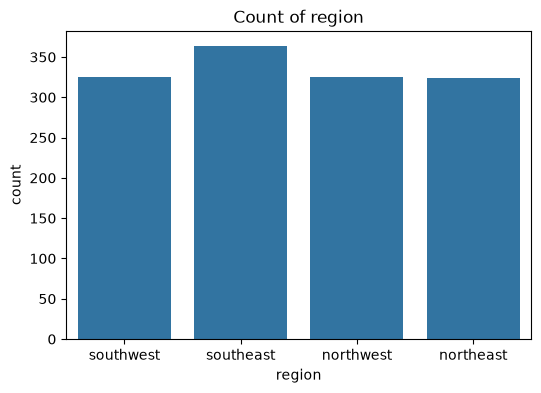

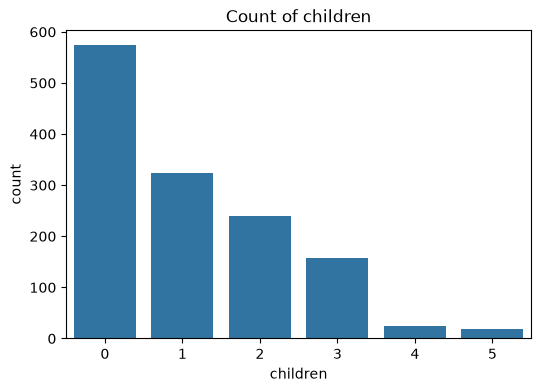

In [9]:
categorical_columns = ["sex", "smoker", "region", "children"]
for col in categorical_columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col, data=df)
    plt.title(f"Count of {col}")
    plt.show()

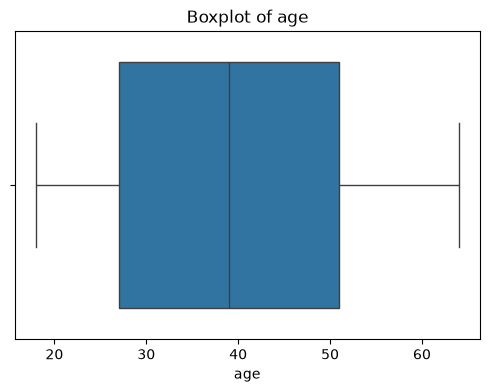

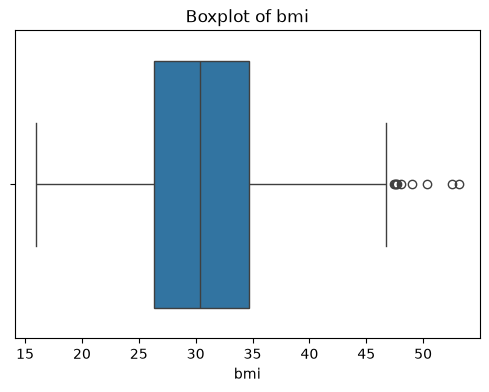

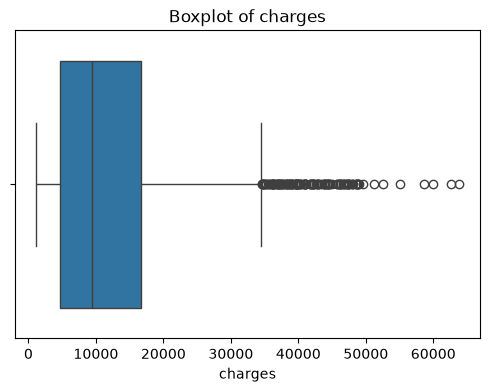

In [10]:
for col in ["age", "bmi", "charges"]:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

#Relationship of each feature with charges

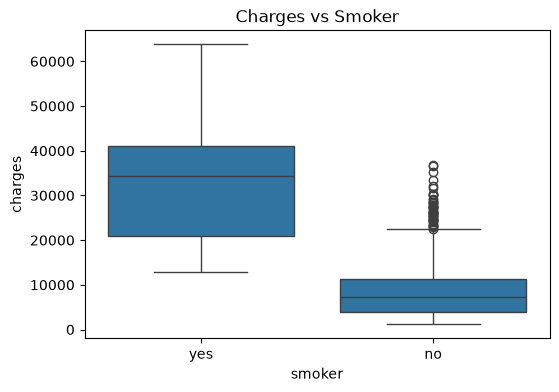

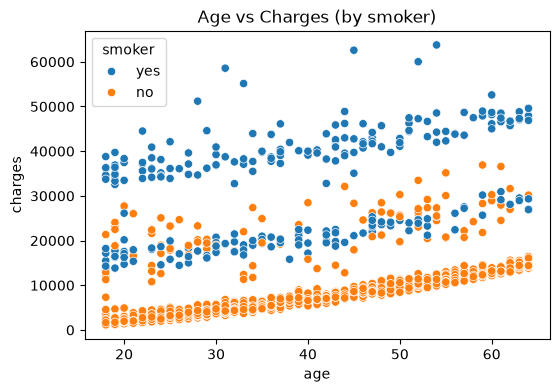

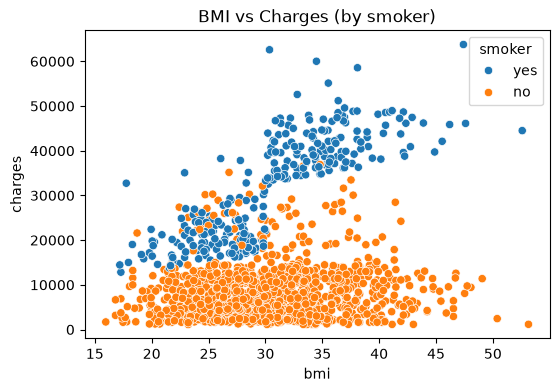

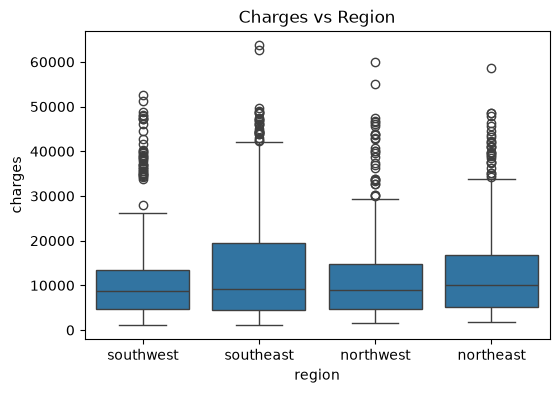

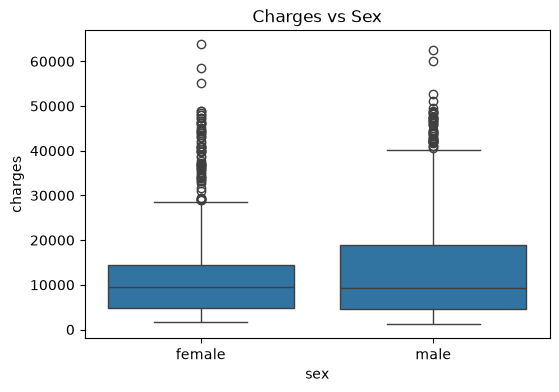

In [11]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Charges vs Smoker")
plt.show()
 
plt.figure(figsize=(6, 4))
sns.scatterplot(x="age", y="charges", hue="smoker", data=df)
plt.title("Age vs Charges (by smoker)")
plt.show()
 
plt.figure(figsize=(6, 4))
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df)
plt.title("BMI vs Charges (by smoker)")
plt.show()
 
plt.figure(figsize=(6, 4))
sns.boxplot(x="region", y="charges", data=df)
plt.title("Charges vs Region")
plt.show()
 
plt.figure(figsize=(6, 4))
sns.boxplot(x="sex", y="charges", data=df)
plt.title("Charges vs Sex")
plt.show()

# Correlation heatmap


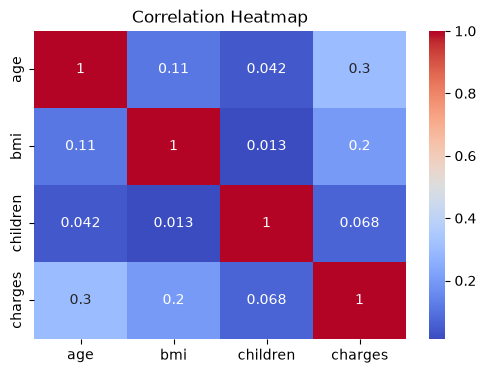

In [12]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [13]:
print(df.groupby("smoker")["charges"].mean())
print(df.groupby("region")["charges"].mean())
print(df.groupby("sex")["charges"].mean())

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64
region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64
sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64


### now we have done EDA

## now we will do data cleaning & pre-proccessing 

we have to remove the repeated row 

In [14]:
df_cleaned = df.copy()
df_cleaned.shape

(1338, 7)

In [15]:
df_cleaned.drop_duplicates(inplace=True)
df_cleaned.shape

(1337, 7)

now we will check null values 

In [16]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

checking data types of all columns

In [17]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

as you can see their SEX , SMOKER & REGION columns are not numeric so we have to make it numeric to train modle 

In [18]:
df_cleaned["sex"].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [19]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male" : 0,"female" : 1})
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830
1334,18,1,31.920,0,no,northeast,2205.98080
1335,18,1,36.850,0,no,southeast,1629.83350
1336,21,1,25.800,0,no,southwest,2007.94500


now encoding smokers columns

In [20]:
df_cleaned["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [21]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no" : 0,"yes" : 1})
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


now we have to encode REGION column 

In [22]:
df_cleaned["region"].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [23]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['region'], drop_first=True, dtype=int)
df_cleaned

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,1
1,18,0,33.770,1,0,1725.55230,0,1,0
2,28,0,33.000,3,0,4449.46200,0,1,0
3,33,0,22.705,0,0,21984.47061,1,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0
1334,18,1,31.920,0,0,2205.98080,0,0,0
1335,18,1,36.850,0,0,1629.83350,0,1,0
1336,21,1,25.800,0,0,2007.94500,0,0,1


Now we have done data cleaning and preprocessing 

## Feature Enginerring and Extraction

now we will divide the BMI in categires

<Axes: xlabel='bmi', ylabel='Count'>

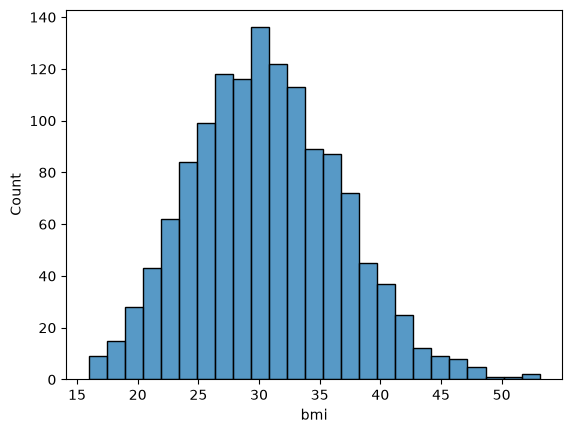

In [24]:
sns.histplot(df["bmi"])

### Adult BMI Categories

| Category | BMI Range |
| :--- | :--- |
| **Underweight** | Less than 18.5 |
| **Healthy Weight** | 18.5 – 24.9 |
| **Overweight** | 25.0 – 29.9 |
| **Obesity Class 1** | 30.0 – 34.9 |
| **Obesity Class 2** | 35.0 – 39.9 |
| **Obesity Class 3 (Severe)** | $\ge$ 40.0 |

In [25]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 25, 30, 35, 40, float('inf')],
    labels=['Underweight', 'Healthy Weight', 'Overweight',
            'Obesity Class 1', 'Obesity Class 2', 'Obesity Class 3'],
    right=False
)

In [26]:
df_cleaned

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,1,0,Obesity Class 1
2,28,0,33.000,3,0,4449.46200,0,1,0,Obesity Class 1
3,33,0,22.705,0,0,21984.47061,1,0,0,Healthy Weight
4,32,0,28.880,0,0,3866.85520,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0,Obesity Class 1
1334,18,1,31.920,0,0,2205.98080,0,0,0,Obesity Class 1
1335,18,1,36.850,0,0,1629.83350,0,1,0,Obesity Class 2
1336,21,1,25.800,0,0,2007.94500,0,0,1,Overweight


In [27]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['bmi_category'], drop_first=True, dtype=int)
df_cleaned

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Healthy Weight,bmi_category_Overweight,bmi_category_Obesity Class 1,bmi_category_Obesity Class 2,bmi_category_Obesity Class 3
0,19,1,27.900,0,1,16884.92400,0,0,1,0,1,0,0,0
1,18,0,33.770,1,0,1725.55230,0,1,0,0,0,1,0,0
2,28,0,33.000,3,0,4449.46200,0,1,0,0,0,1,0,0
3,33,0,22.705,0,0,21984.47061,1,0,0,1,0,0,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0,0,0,1,0,0
1334,18,1,31.920,0,0,2205.98080,0,0,0,0,0,1,0,0
1335,18,1,36.850,0,0,1629.83350,0,1,0,0,0,0,1,0
1336,21,1,25.800,0,0,2007.94500,0,0,1,0,1,0,0,0


In [28]:
from sklearn.preprocessing import StandardScaler
cols = ["age", "bmi", "children"]
scaler = StandardScaler()
df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [29]:
df_cleaned

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Healthy Weight,bmi_category_Overweight,bmi_category_Obesity Class 1,bmi_category_Obesity Class 2,bmi_category_Obesity Class 3
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,1,0,1,0,0,0
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,1,0,0,0,1,0,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,1,0,0,0,1,0,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,1,0,0,1,0,0,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,0.050269,1.580143,0,10600.54830,1,0,0,0,0,1,0,0
1334,-1.511647,1,0.206053,-0.909234,0,2205.98080,0,0,0,0,0,1,0,0
1335,-1.511647,1,1.014490,-0.909234,0,1629.83350,0,1,0,0,0,0,1,0
1336,-1.297958,1,-0.797524,-0.909234,0,2007.94500,0,0,1,0,1,0,0,0


now we have done feature eng. and scaling

## so now we have to check the co-relatios bw the columns and charges 

### pearson co-relation 

In [30]:
from scipy.stats import pearsonr

# Person co-relation checking

# list of coloums to check relation b/w CHARGES and These columns
selected_features = [
    'age',
    'sex',
    'bmi',
    'children',
    'smoker',
    'region_northwest',
    'region_southeast',
    'region_southwest',
    'bmi_category_Healthy Weight',
    'bmi_category_Overweight',
    'bmi_category_Obesity Class 1',
    'bmi_category_Obesity Class 2',
    'bmi_category_Obesity Class 3'
]

correlations = {}

for feature in selected_features:
    result = pearsonr(
        df_cleaned[feature],
        df_cleaned['charges']
    )

    correlations[feature] = result[0]

correlations

{'age': np.float64(0.29830821250978634),
 'sex': np.float64(-0.05804449579031286),
 'bmi': np.float64(0.1984008312262494),
 'children': np.float64(0.0673893508396325),
 'smoker': np.float64(0.7872343672800316),
 'region_northwest': np.float64(-0.038694632621016446),
 'region_southeast': np.float64(0.07357792870627781),
 'region_southwest': np.float64(-0.04363736849776148),
 'bmi_category_Healthy Weight': np.float64(-0.10663345359401079),
 'bmi_category_Overweight': np.float64(-0.12060070272348657),
 'bmi_category_Obesity Class 1': np.float64(0.062198560217583805),
 'bmi_category_Obesity Class 2': np.float64(0.13908492720701998),
 'bmi_category_Obesity Class 3': np.float64(0.0782557654798458)}

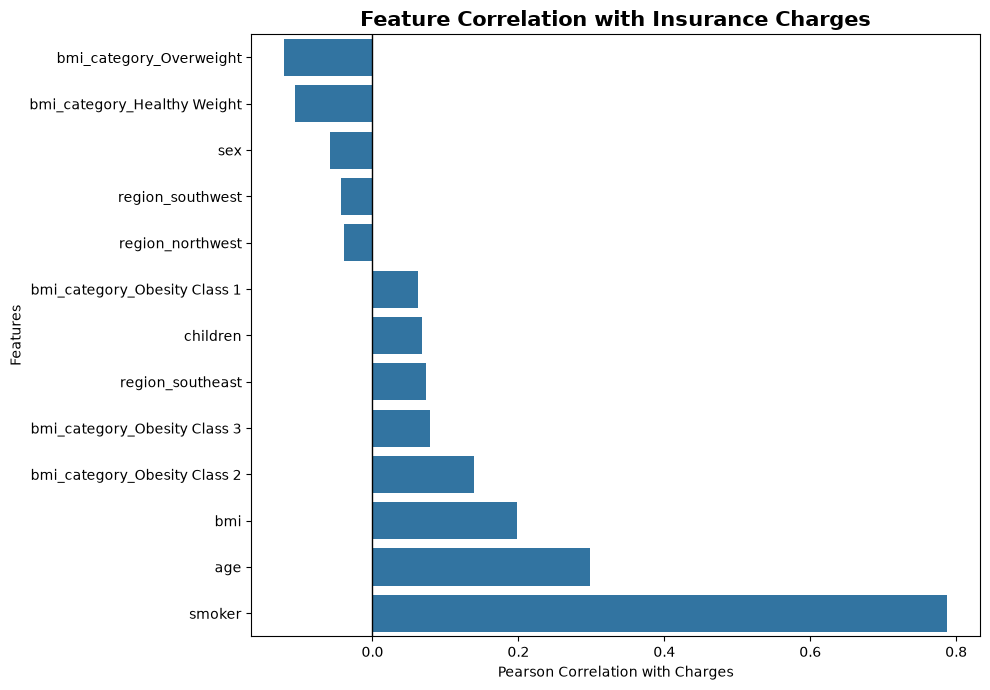

In [31]:
target_corr = (
    df_cleaned.corr(numeric_only=True)["charges"]
    .drop("charges")
    .sort_values()
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Pearson Correlation with Charges")
plt.ylabel("Features")
plt.title(
    "Feature Correlation with Insurance Charges",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

In [32]:
df_corr = pd.DataFrame(
    correlations.items(),
    columns=["Feature", "Correlation"],
)

df_corr.sort_values(by="Correlation" ,ascending=False)

,Feature,Correlation
4,smoker,0.787234
0,age,0.298308
2,bmi,0.198401
11,bmi_category_Obesity Class 2,0.139085
12,bmi_category_Obesity Class 3,0.078256
6,region_southeast,0.073578
3,children,0.067389
10,bmi_category_Obesity Class 1,0.062199
5,region_northwest,-0.038695
7,region_southwest,-0.043637


## Dividing the data into training and testing sets.

### Separating the features and target columns

In [33]:
X = df_cleaned.drop(columns=["charges"])
y = df_cleaned["charges"]

### 80% train / 20% test

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1069, 13)
X_test: (268, 13)
y_train: (1069,)
y_test: (268,)


## Training and Comparing Three Machine Learning Models

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).sort_values("R2 Score", ascending=False))

               Model        MAE       RMSE  R2 Score
2  Gradient Boosting  2528.9452  4308.0448    0.8990
1      Random Forest  2553.4000  4499.1414    0.8898
0  Linear Regression  4317.3965  6023.9267    0.8025


### Gradient Boosting Performs Best Among the Three Models

As we can see from the above results, Gradient Boosting achieves the best performance among the three machine learning algorithms, with an R² score of **0.8990 (89.90%)**, an MAE of **2528.95**, and an RMSE of **4308.04**.

Therefore, Gradient Boosting is selected as the best-performing model for predicting insurance charges based on the current test results.

In [ ]:
# # User input
# age = 18
# sex = "female"
# bmi = 31.35
# children = 0
# smoker = "yes"
# region = "southeast"

# # Create input dataframe
# input_data = pd.DataFrame([{
#     "age": age,
#     "sex": 1 if sex == "male" else 0,
#     "bmi": bmi,
#     "children": children,
#     "smoker": 1 if smoker == "yes" else 0,
#     "region_northwest": int(region == "northwest"),
#     "region_southeast": int(region == "southeast"),
#     "region_southwest": int(region == "southwest"),
# }])

# # BMI categories — training mein use kiye gaye same rules hone chahiye
# input_data["bmi_category_Healthy Weight"] = int(18.5 <= bmi < 25)
# input_data["bmi_category_Overweight"] = int(25 <= bmi < 30)
# input_data["bmi_category_Obesity Class 1"] = int(30 <= bmi < 35)
# input_data["bmi_category_Obesity Class 2"] = int(35 <= bmi < 40)
# input_data["bmi_category_Obesity Class 3"] = int(bmi >= 40)

# # Keep exactly the same feature order
# input_data = input_data[X.columns]

# # Scale using your already-fitted scaler
# input_data[["age", "bmi", "children"]] = scaler.transform(
#     input_data[["age", "bmi", "children"]]
# )

# # Predict
# model = models["Gradient Boosting"]
# prediction = model.predict(input_data)[0]

# print(f"Estimated Insurance Charges: ${prediction:,.2f}")

Estimated Insurance Charges: $34,755.55


Saving the modle

In [48]:
import joblib
import os

print("Joblib installed:", joblib.__version__)
print("Model available:", "Gradient Boosting" in models)
print("Scaler available:", "scaler" in globals())

bundle = {
    "model": models["Gradient Boosting"],
    "scaler": scaler,
    "feature_columns": X.columns.tolist(),
    "scaled_columns": ["age", "bmi", "children"]
}

joblib.dump(bundle, "insurance_model.pkl")

print("File exists:", os.path.exists("insurance_model.pkl"))
print("File location:", os.path.abspath("insurance_model.pkl"))

Joblib installed: 1.6.0
Model available: True
Scaler available: True
File exists: True
File location: e:\Machine Learning\ML01\Project 01\insurance_model.pkl
